## Week 0: EDA & Setup

In [1]:
%pip install pandas numpy matplotlib scikit-learn statsmodels
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, cross_val_predict, GridSearchCV, validation_curve)
from sklearn.linear_model import (LinearRegression, LogisticRegression, LogisticRegressionCV,
                                  RidgeCV, LassoCV, ElasticNetCV)
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.svm import LinearSVC, SVC, SVR
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             log_loss, mean_squared_error, r2_score, roc_auc_score, roc_curve,
                             RocCurveDisplay)

Note: you may need to restart the kernel to use updated packages.


In [2]:
raw = pd.read_csv("aei_claude_ai_2026-06-26.csv", dtype={"node_external_id": str})
raw["category_name"].value_counts()

category_name
onet              744544
request           465202
soc_occupation    353817
overall            73010
Name: count, dtype: int64

In [3]:
keep = raw[(raw["geo_level"] == "global") &
           (raw["hierarchy_level"] == 0) &
           (raw["date_start"] == "2026-05-01") &
           (raw["category_name"].isin(["onet", "soc_occupation"]))]

print("Rows kept:", len(keep), "of", len(raw))
keep.head()

Rows kept: 174864 of 1636573


,date_start,date_end,geo_id,geo_level,category_name,hierarchy_level,metric_id,value,node_name,node_external_id
1700,2026-05-01,2026-06-01,GLOBAL,global,soc_occupation,0,ai_autonomy_mean,2.47,Recreational Vehicle Service Technicians,49-3092.00
1701,2026-05-01,2026-06-01,GLOBAL,global,soc_occupation,0,ai_autonomy_mean,2.59,Gambling and Sports Book Writers and Runners,39-3012.00
1702,2026-05-01,2026-06-01,GLOBAL,global,soc_occupation,0,ai_autonomy_mean,2.72,Occupational Therapists,29-1122.00
1703,2026-05-01,2026-06-01,GLOBAL,global,soc_occupation,0,ai_autonomy_mean,2.82,"Multiple Machine Tool Setters, Operators, and ...",51-4081.00
1704,2026-05-01,2026-06-01,GLOBAL,global,soc_occupation,0,ai_autonomy_mean,2.65,"Library Science Teachers, Postsecondary",25-1082.00


## Step 2: Turn the long table into a normal table (one row per task / occupation)
`pivot_table` turns each metric name into its own column.

In [4]:
def make_table(category):
    part = keep[keep["category_name"] == category]
    wide = part.pivot_table(index=["node_external_id", "node_name"],
                            columns="metric_id", values="value").reset_index()
    return wide

tasks = make_table("onet")                # one row per work task

print("Tasks:", tasks.shape)
tasks.head(3)

Tasks: (2713, 53)


metric_id,node_external_id,node_name,ai_autonomy_mean,ai_education_years_mean,artifact_academic_paper_or_thesis_pct,artifact_advice_or_recommendation_pct,artifact_analysis_or_summary_pct,artifact_app_or_website_pct,artifact_audio_or_music_pct,artifact_blog_or_article_pct,...,collaboration_validation_pct,human_education_years_mean,human_only_ability_pct,human_only_time_mean,human_with_ai_time_mean,multitasking_pct,pct,use_case_coursework_pct,use_case_personal_pct,use_case_work_pct
0,1,Resolve customer complaints regarding sales an...,2.37,10.25,0.0,12.3,2.46,0.00,0.0,0.0,...,0.83,9.65,97.54,2.39,49.05,53.28,0.0,1.64,29.51,68.85
1,10009,"List parts needed, estimate costs, and plan wo...",3.12,12.56,0.0,4.0,4.00,0.00,0.0,0.0,...,4.17,12.16,84.00,6.98,33.04,8.00,0.0,4.00,24.00,72.00
2,10027,Explain assembly procedures or techniques to o...,2.59,12.35,0.0,0.0,0.00,11.76,0.0,0.0,...,0.00,11.35,64.71,5.69,67.44,17.65,0.0,52.94,35.29,11.76


## Step 3: Create the target (time savings)
- `human_only_time_mean` is in **hours**; `human_with_ai_time_mean` is in **minutes**. We convert hours to minutes first.
- `time_savings` = how many times faster the task is with AI (7.5 means 7.5x faster).
- We also make `high_savings` (1 if above the median, else 0) for the classification weeks.

In [5]:
def add_target(df):
    df = df.dropna(subset=["human_only_time_mean", "human_with_ai_time_mean"]).copy()
    df = df[df["human_with_ai_time_mean"] > 0]
    df["time_savings"] = (df["human_only_time_mean"] * 60) / df["human_with_ai_time_mean"]
    df["log_time_savings"] = np.log(df["time_savings"])
    return df

tasks = add_target(tasks)
minimum = tasks["time_savings"].min()
q1 = tasks["time_savings"].quantile(0.25)   # 25% of values are below this
q2 = tasks["time_savings"].quantile(0.50)   # the median
q3 = tasks["time_savings"].quantile(0.75)   # 75% of values are below this                # interquartile range (the middle 50% of the data)
maximum = tasks["time_savings"].max()

print("Min:", minimum)
print("Q1:", q1)
print("Median:", q2)
print("Q3:", q3)
print("Max:", maximum)

Min: 0.7163221667854598
Q1: 4.7759474549695975
Median: 7.539808917197453
Q3: 10.878776576598554
Max: 65.99999999999999


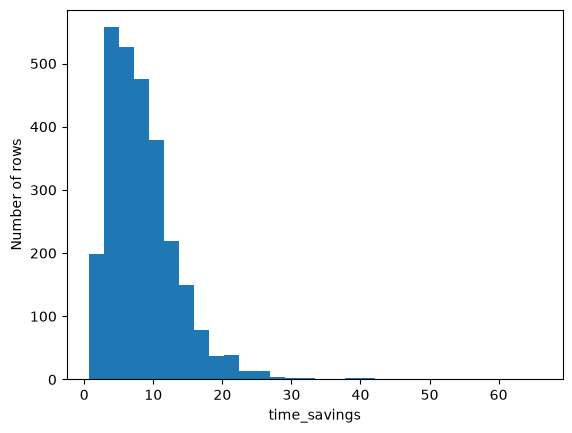

In [6]:
plt.hist(tasks["time_savings"], bins=30)
plt.xlabel("time_savings")
plt.ylabel("Number of rows")
plt.show()

In [7]:
tasks["log_time_savings"] = np.log(tasks["time_savings"])
tasks = add_target(tasks)
minimum = tasks["log_time_savings"].min()
q1 = tasks["log_time_savings"].quantile(0.25)   # 25% of values are below this
q2 = tasks["log_time_savings"].quantile(0.50)   # the median
q3 = tasks["log_time_savings"].quantile(0.75)   # 75% of values are below this                # interquartile range (the middle 50% of the data)
maximum = tasks["log_time_savings"].max()

print("Min:", minimum)
print("Q1:", q1)
print("Median:", q2)
print("Q3:", q3)
print("Max:", maximum)

Min: -0.33362525960928474
Q1: 1.563592233433004
Median: 2.0201968391519802
Q3: 2.3868137648169974
Max: 4.189654742026425


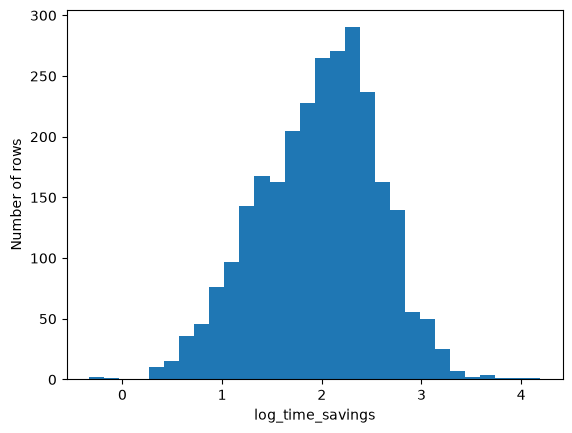

In [8]:
plt.hist(tasks["log_time_savings"], bins=30)
plt.xlabel("log_time_savings")
plt.ylabel("Number of rows")
plt.show()

In [9]:
tasks.columns

Index(['node_external_id', 'node_name', 'ai_autonomy_mean',
       'ai_education_years_mean', 'artifact_academic_paper_or_thesis_pct',
       'artifact_advice_or_recommendation_pct',
       'artifact_analysis_or_summary_pct', 'artifact_app_or_website_pct',
       'artifact_audio_or_music_pct', 'artifact_blog_or_article_pct',
       'artifact_chart_or_visualization_pct', 'artifact_code_fix_or_debug_pct',
       'artifact_config_or_infra_pct', 'artifact_creative_writing_pct',
       'artifact_data_or_spreadsheet_pct', 'artifact_document_or_report_pct',
       'artifact_educational_material_pct', 'artifact_email_or_message_pct',
       'artifact_explanation_or_answer_pct',
       'artifact_game_or_interactive_pct', 'artifact_idea_or_brainstorm_pct',
       'artifact_image_or_graphic_pct',
       'artifact_marketing_or_social_content_pct',
       'artifact_math_or_calculation_pct', 'artifact_ml_or_ai_system_pct',
       'artifact_none_pct', 'artifact_other_pct',
       'artifact_plan_or_st

In [10]:
tasks_cut = tasks.drop(columns=["time_savings", "node_external_id", "node_name", "human_only_time_mean", "human_with_ai_time_mean", "pct",
"collaboration_bucket_augmentation_pct", "collaboration_bucket_automation_pct", "collaboration_none_pct", "use_case_personal_pct", "artifact_none_pct"])

print(tasks_cut.shape) 

(2703, 44)


In [11]:
# Remove the same number of rows with any blank values just for simplicity
tasks_cut = tasks_cut.dropna().copy()
print(tasks_cut.shape)

(2697, 44)


In [12]:
corr = tasks_cut.corr() 
target_corr = corr["log_time_savings"].drop("log_time_savings")
print(target_corr.sort_values(key=abs, ascending=False).round(2))

metric_id
ai_autonomy_mean                            0.60
artifact_advice_or_recommendation_pct      -0.54
ai_education_years_mean                     0.51
human_education_years_mean                  0.48
use_case_work_pct                           0.47
collaboration_feedback_loop_pct            -0.46
collaboration_directive_pct                 0.41
artifact_explanation_or_answer_pct         -0.39
artifact_document_or_report_pct             0.39
collaboration_task_iteration_pct            0.38
human_only_ability_pct                     -0.36
collaboration_learning_pct                 -0.35
multitasking_pct                           -0.26
artifact_presentation_or_slides_pct         0.26
artifact_data_or_spreadsheet_pct            0.24
artifact_app_or_website_pct                 0.23
artifact_chart_or_visualization_pct         0.20
artifact_email_or_message_pct              -0.16
artifact_academic_paper_or_thesis_pct       0.15
artifact_ui_or_design_mockup_pct            0.14
use_case_c

In [13]:
y = tasks_cut["log_time_savings"]  
X = tasks_cut.drop(columns=["log_time_savings"])

## Week 1: Polynomial and Interaction Terms

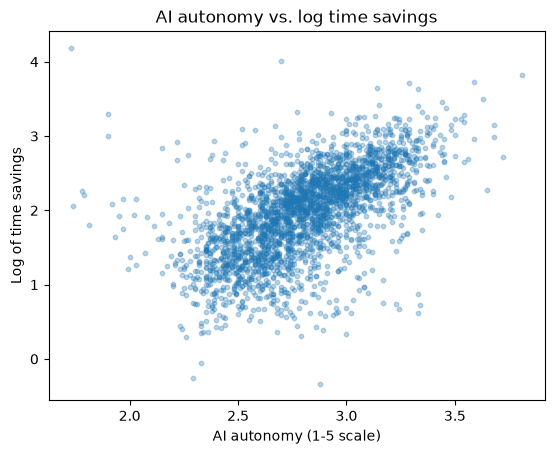

In [14]:
plt.scatter(X["ai_autonomy_mean"], y, alpha=0.3, s=10)
plt.xlabel("AI autonomy (1-5 scale)")
plt.ylabel("Log of time savings")
plt.title("AI autonomy vs. log time savings")
plt.show()

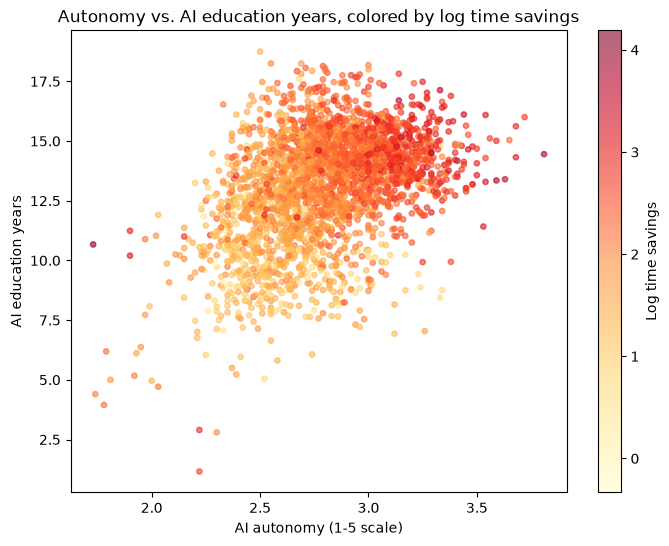

In [15]:
plt.figure(figsize=(8, 6))
points = plt.scatter(X["ai_autonomy_mean"], X["ai_education_years_mean"],
                     c=y, cmap="YlOrRd", alpha=0.6, s=15)
plt.colorbar(points, label="Log time savings")
plt.xlabel("AI autonomy (1-5 scale)")
plt.ylabel("AI education years")
plt.title("Autonomy vs. AI education years, colored by log time savings")
plt.show()

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [17]:
# Baseline Model
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, r2_score

# ---------- 1. Fit the regression on the training data ----------
X_train_sm = sm.add_constant(X_train)          # add the intercept
model = sm.OLS(y_train, X_train_sm).fit()     # predict log time savings

print(f"Train R2: {model.rsquared:.3f}   Adj R2: {model.rsquared_adj:.3f}")

# ---------- 2. Score it on the locked test set ----------
X_test_sm = sm.add_constant(X_test, has_constant="add")
pred = model.predict(X_test_sm)

rmse = np.sqrt(mean_squared_error(y_test, pred))
print(f"Test R2: {r2_score(y_test, pred):.3f}   Test RMSE: {rmse:.3f} (log units)")

# ---------- 3. Strongest coefficients ----------
coef = pd.DataFrame({"coef": model.params, "p_value": model.pvalues, "abs_t": model.tvalues.abs()}).drop("const")
print(coef.sort_values("abs_t", ascending=False).head(10).round(3))

Train R2: 0.714   Adj R2: 0.708
Test R2: 0.752   Test RMSE: 0.301 (log units)
                                        coef  p_value  abs_t
ai_autonomy_mean                       0.366      0.0  8.735
multitasking_pct                      -0.006      0.0  6.527
artifact_advice_or_recommendation_pct -0.008      0.0  6.145
artifact_config_or_infra_pct          -0.010      0.0  5.988
collaboration_feedback_loop_pct       -0.009      0.0  5.430
artifact_app_or_website_pct            0.010      0.0  5.277
use_case_work_pct                      0.003      0.0  5.141
collaboration_directive_pct            0.007      0.0  4.434
human_only_ability_pct                -0.004      0.0  4.341
artifact_email_or_message_pct         -0.005      0.0  3.891


In [18]:
# Adding an interaction and squared features
X_train["autonomy_edu"] = X_train["ai_autonomy_mean"] * X_train["ai_education_years_mean"]
X_train["autonomy_sq"] = X_train["ai_autonomy_mean"] ** 2

X_test["autonomy_edu"] = X_test["ai_autonomy_mean"] * X_test["ai_education_years_mean"]
X_test["autonomy_sq"] = X_test["ai_autonomy_mean"] ** 2

In [19]:
# ---------- 1. Fit the regression on the training data ----------
X_train_sm = sm.add_constant(X_train)          # add the intercept
model = sm.OLS(y_train, X_train_sm).fit()     # predict log time savings

print(f"Added terms: Train R2: {model.rsquared:.3f}   Adj R2: {model.rsquared_adj:.3f}")

# ---------- 2. Score it on the locked test set ----------
X_test_sm = sm.add_constant(X_test, has_constant="add")
pred = model.predict(X_test_sm)

rmse = np.sqrt(mean_squared_error(y_test, pred))
print(f"Added terms: Test R2: {r2_score(y_test, pred):.3f}   Test RMSE: {rmse:.3f} (log units)")

# ---------- 3. Strongest coefficients ----------
coef = pd.DataFrame({"coef": model.params, "p_value": model.pvalues, "abs_t": model.tvalues.abs()}).drop("const")
print(coef.sort_values("abs_t", ascending=False).head(10).round(3))

Added terms: Train R2: 0.734   Adj R2: 0.729
Added terms: Test R2: 0.765   Test RMSE: 0.293 (log units)
                                        coef  p_value  abs_t
autonomy_edu                           0.127      0.0  9.025
artifact_advice_or_recommendation_pct -0.009      0.0  7.690
artifact_config_or_infra_pct          -0.012      0.0  7.212
ai_autonomy_mean                      -2.890      0.0  7.095
use_case_work_pct                      0.003      0.0  5.853
collaboration_feedback_loop_pct       -0.010      0.0  5.828
artifact_explanation_or_answer_pct    -0.007      0.0  5.795
artifact_email_or_message_pct         -0.007      0.0  5.769
ai_education_years_mean               -0.208      0.0  5.462
multitasking_pct                      -0.005      0.0  5.389


## Week 2: Lasso, ridge, elastic net regression 

In [20]:
# ---------- 1. Scaling the features ----------
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)      # learn the scale from training data
X_test_s = scaler.transform(X_test)            # apply it to test data

# ---------- 2. Fitting the models ----------
alphas = np.logspace(-5, 2, 50)                # penalty strengths from 0.00001 to 100

ols = LinearRegression().fit(X_train_s, y_train)                                          # no penalty
ridge = RidgeCV(alphas=alphas, cv=5).fit(X_train_s, y_train)
lasso = LassoCV(alphas=alphas, cv=5, random_state=42, max_iter=10000).fit(X_train_s, y_train)
enet = ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], alphas=alphas, cv=5, random_state=42, max_iter=10000).fit(X_train_s, y_train)

print("Best alpha - Ridge:", ridge.alpha_)
print("Best alpha - Lasso:", lasso.alpha_)
print("Best alpha - Elastic Net:", enet.alpha_, "| l1_ratio:", enet.l1_ratio_)

# ---------- 3. Comparing performance ----------
def score(model, name):
    pred = model.predict(X_test_s)
    print(name, "| Test R2:", round(r2_score(y_test, pred), 3),
          "| Test RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))

score(ols, "OLS")
score(ridge, "Ridge")
score(lasso, "Lasso")
score(enet, "Elastic Net")

# ---------- 4. Comparing coefficients ----------
coefs = pd.DataFrame({"OLS": ols.coef_, "Ridge": ridge.coef_,
                      "Lasso": lasso.coef_, "Elastic Net": enet.coef_},
                     index=X_train.columns).round(3)
print("Features kept (not zero):", (coefs != 0).sum().to_dict())
print(coefs.sort_values("Lasso", key=abs, ascending=False).head(10))

Best alpha - Ridge: 0.2682695795279722
Best alpha - Lasso: 5.1794746792312125e-05
Best alpha - Elastic Net: 7.196856730011514e-05 | l1_ratio: 0.5
OLS | Test R2: 0.765 | Test RMSE: 0.293
Ridge | Test R2: 0.765 | Test RMSE: 0.293
Lasso | Test R2: 0.765 | Test RMSE: 0.293
Elastic Net | Test R2: 0.765 | Test RMSE: 0.293
Features kept (not zero): {'OLS': 44, 'Ridge': 45, 'Lasso': 44, 'Elastic Net': 44}
                                         OLS  Ridge  Lasso  Elastic Net
metric_id                                                              
autonomy_edu                           1.055  1.016  1.038        1.032
ai_autonomy_mean                      -0.813 -0.774 -0.781       -0.780
ai_education_years_mean               -0.474 -0.452 -0.465       -0.461
autonomy_sq                            0.457  0.435  0.432        0.433
human_education_years_mean            -0.177 -0.172 -0.173       -0.173
collaboration_feedback_loop_pct       -0.148 -0.148 -0.152       -0.151
artifact_advice_or_reco

The different regularization methods did not help the original model at all. The Lasso and elastic methods both picked alphas of less than or equal to 0.00007, which is extremely close to have basically no penalty. 

## Week 3: Forward and backward selection, principal component regression, partial least squares regression



In [21]:
# ---------- Baseline: all 45 features ----------
full = LinearRegression().fit(X_train_s, y_train)
print("All features Test R²:", full.score(X_test_s, y_test))

# ---------- Forward selection ----------
selector = SequentialFeatureSelector(LinearRegression(), n_features_to_select=10, direction='forward')
selector.fit(X_train_s, y_train)

forward_chosen = X_train.columns[selector.get_support()]      # which features got picked
print(forward_chosen)

fwd_model = LinearRegression().fit(X_train_s[:, selector.get_support()], y_train)
print("Forward Test R²:", fwd_model.score(X_test_s[:, selector.get_support()], y_test))

# ---------- Backward selection ----------
backward = SequentialFeatureSelector(LinearRegression(), n_features_to_select=10, direction='backward')
backward.fit(X_train_s, y_train)

chosen_backward = X_train.columns[backward.get_support()]     # which features survived
print(chosen_backward)

bwd_model = LinearRegression().fit(X_train_s[:, backward.get_support()], y_train)
print("Backward Test R²:", bwd_model.score(X_test_s[:, backward.get_support()], y_test))

# ---------- PCA: how many components? ----------
pca = PCA()                       # no number specified yet, just see what's possible
pca.fit(X_train_s)
print(pca.explained_variance_ratio_[:10].round(3))        # first 10 components
print(np.cumsum(pca.explained_variance_ratio_).round(2))  # running total

loadings = pd.DataFrame(pca.components_.T,
                        columns=[f'PC{i+1}' for i in range(pca.n_components_)],
                        index=X_train.columns)
print(loadings[["PC1", "PC2", "PC3"]].round(2))

# ---------- PCR and PLSR for several numbers of components ----------
for n in [5, 10, 15, 20, 30]:
    pca_n = PCA(n_components=n)
    X_train_pca = pca_n.fit_transform(X_train_s)
    X_test_pca = pca_n.transform(X_test_s)
    pcr_model = LinearRegression().fit(X_train_pca, y_train)

    pls = PLSRegression(n_components=n).fit(X_train_s, y_train)

    print(n, "components | PCR Test R²:", round(pcr_model.score(X_test_pca, y_test), 3),
          "| PLSR Test R²:", round(pls.score(X_test_s, y_test), 3))

All features Test R²: 0.7651767856647104
Index(['ai_autonomy_mean', 'ai_education_years_mean',
       'artifact_advice_or_recommendation_pct', 'artifact_app_or_website_pct',
       'artifact_data_or_spreadsheet_pct', 'collaboration_directive_pct',
       'collaboration_feedback_loop_pct', 'collaboration_learning_pct',
       'multitasking_pct', 'autonomy_edu'],
      dtype='str', name='metric_id')
Forward Test R²: 0.7226394644045335
Index(['ai_autonomy_mean', 'ai_education_years_mean',
       'artifact_advice_or_recommendation_pct', 'artifact_app_or_website_pct',
       'artifact_config_or_infra_pct', 'artifact_email_or_message_pct',
       'artifact_explanation_or_answer_pct', 'collaboration_directive_pct',
       'collaboration_feedback_loop_pct', 'autonomy_edu'],
      dtype='str', name='metric_id')
Backward Test R²: 0.7171498337485906
[0.14  0.068 0.061 0.055 0.048 0.035 0.033 0.033 0.03  0.028]
[0.14 0.21 0.27 0.32 0.37 0.41 0.44 0.47 0.5  0.53 0.56 0.58 0.6  0.63
 0.65 0.67 0.7  

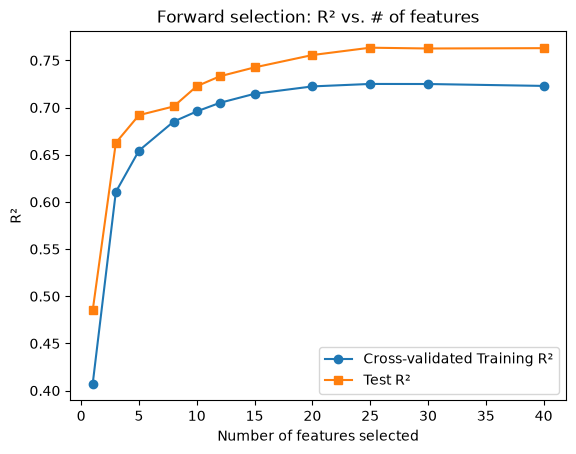

In [22]:
sizes = [1, 3, 5, 8, 10, 12, 15, 20, 25, 30, 40]    # trying different sizes of features to keep (there are 45 in total)
cv_scores = []
test_scores = []

for n in sizes:
    selector = SequentialFeatureSelector(LinearRegression(), n_features_to_select=n, direction="forward")
    selector.fit(X_train_s, y_train)
    keep = selector.get_support()                 
    cv_scores.append(cross_val_score(LinearRegression(), X_train_s[:, keep], y_train, cv=5, scoring="r2").mean())
    test_scores.append(LinearRegression().fit(X_train_s[:, keep], y_train).score(X_test_s[:, keep], y_test))

plt.plot(sizes, cv_scores, marker="o", label="Cross-validated Training R²")
plt.plot(sizes, test_scores, marker="s", label="Test R²")
plt.xlabel("Number of features selected")
plt.ylabel("R²")
plt.title("Forward selection: R² vs. # of features")
plt.legend()
plt.show()

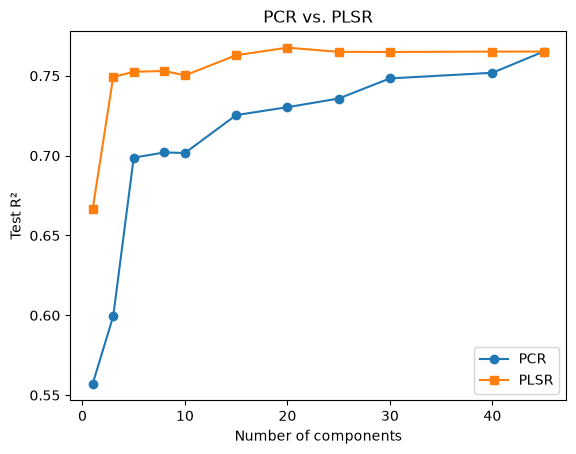

In [23]:
comps = [1, 3, 5, 8, 10, 15, 20, 25, 30, 40, 45]
pcr_r2 = []
pls_r2 = []

for n in comps:
    pca_n = PCA(n_components=n)
    X_train_pca = pca_n.fit_transform(X_train_s)
    pcr_r2.append(LinearRegression().fit(X_train_pca, y_train).score(pca_n.transform(X_test_s), y_test))
    pls_r2.append(PLSRegression(n_components=n).fit(X_train_s, y_train).score(X_test_s, y_test))

plt.plot(comps, pcr_r2, marker="o", label="PCR")
plt.plot(comps, pls_r2, marker="s", label="PLSR")
plt.xlabel("Number of components")
plt.ylabel("Test R²")
plt.title("PCR vs. PLSR")
plt.legend()
plt.show()

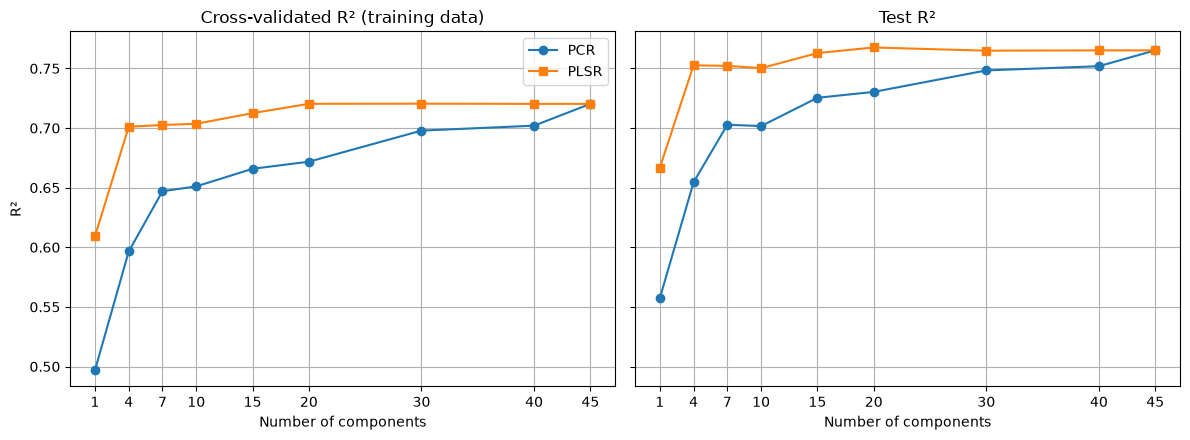

In [24]:
comps = [1, 4, 7, 10, 15, 20, 30, 40, 45]
pcr_cv, pls_cv = [], []        # cross-validated R² (training data)
pcr_test, pls_test = [], []    # test R²

for n in comps:
    # cross-validated scores
    pcr_cv.append(cross_val_score(make_pipeline(PCA(n_components=n), LinearRegression()),
                                  X_train_s, y_train, cv=5, scoring="r2").mean())
    pls_cv.append(cross_val_score(PLSRegression(n_components=n),
                                  X_train_s, y_train, cv=5, scoring="r2").mean())

    # test scores
    pca_n = PCA(n_components=n)
    X_train_pca = pca_n.fit_transform(X_train_s)
    pcr_test.append(LinearRegression().fit(X_train_pca, y_train).score(pca_n.transform(X_test_s), y_test))
    pls_test.append(PLSRegression(n_components=n).fit(X_train_s, y_train).score(X_test_s, y_test))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

axes[0].plot(comps, pcr_cv, marker="o", label="PCR")
axes[0].plot(comps, pls_cv, marker="s", label="PLSR")
axes[0].set_title("Cross-validated R² (training data)")

axes[1].plot(comps, pcr_test, marker="o", label="PCR")
axes[1].plot(comps, pls_test, marker="s", label="PLSR")
axes[1].set_title("Test R²")

for ax in axes:
    ax.set_xticks(comps)                       # label every number you tested
    ax.set_xlabel("Number of components")
    ax.grid(True)
axes[0].set_ylabel("R²")
axes[0].legend()

plt.tight_layout()
plt.show()

## Week 4: Logistic regression and feature scaling

Since this model has a numeric dependent variable, I spent my time with week 4 concepts on the claims fraud dataset.

## Week 5: Support vector machines, the kernel trick, and regularization

In [25]:
# ---------- 1. Linear and RBF SVR ----------
linear_svr = make_pipeline(StandardScaler(), SVR(kernel="linear", C=1.0))
rbf_svr = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=1.0, gamma="scale"))

for name, model in [("Linear SVR", linear_svr), ("RBF SVR", rbf_svr)]:
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name, "| Test R2:", round(r2_score(y_test, pred), 3),
          "| Test RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))

# ---------- 2. Tune C and gamma for the RBF model ----------
rbf_grid = GridSearchCV(
    make_pipeline(StandardScaler(), SVR(kernel="rbf")),
    param_grid={"svr__C": [0.1, 1, 10, 100], "svr__gamma": [0.001, 0.01, "scale"]},
    scoring="r2", cv=5)
rbf_grid.fit(X_train, y_train)

print("Best RBF settings:", rbf_grid.best_params_, "| CV R2:", round(rbf_grid.best_score_, 3))
pred = rbf_grid.predict(X_test)
print("Tuned RBF SVR | Test R2:", round(r2_score(y_test, pred), 3),
      "| Test RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))

Linear SVR | Test R2: 0.767 | Test RMSE: 0.292
RBF SVR | Test R2: 0.825 | Test RMSE: 0.253
Best RBF settings: {'svr__C': 10, 'svr__gamma': 0.01} | CV R2: 0.781
Tuned RBF SVR | Test R2: 0.822 | Test RMSE: 0.255


## Week 6: Decision trees and random forests

Used Week 6 concepts on my claims fraud dataset instead.